# Notebook 14 — Evaluation, Calibration & Statistical Analysis

**Project:** Report-Guided Weak Supervision for Multi-Label Knee MRI Abnormality Detection

## Objective
Evaluate the out-of-fold (OOF) predictions produced by Notebook 13. This notebook does **not** retrain models. It:
- validates OOF coverage and the original five-fold structure;
- reports threshold-based and ranking metrics for all 12 findings;
- compares the three supervision strategies;
- estimates uncertainty with paired study-level bootstrap confidence intervals;
- assesses probability calibration using Brier score, log loss, calibration curves and expected calibration error (ECE);
- saves publication-ready CSV tables and plots.

## Scope
The current experiment contains 58 gold-labelled studies with 10,528 DINOv2 embedding instances. It does not include the 4,349 report-only studies because they do not have MRI embeddings in the current Notebook 09 cache.

**Statistical caution:** OOF predictions are used once for evaluation. Calibration plots and Brier/ECE are descriptive; this notebook does not fit a calibrator and evaluate it on the same OOF data. Threshold = 0.50 is fixed in advance. Bootstrap intervals describe study-sampling uncertainty, not independent external validation.

## 1. Configuration and imports

Attach:
- the RSNA dataset containing `train.csv`;
- Notebook 13 output containing `oof_predictions_all_modes.csv`.

No GPU is needed.

In [1]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, hamming_loss,
    brier_score_loss, log_loss, confusion_matrix
)
warnings.filterwarnings("ignore")

SEED = 42
N_FOLDS = 5
THRESHOLD = 0.50
N_BOOTSTRAP = 2000
ECE_BINS = 10
RANDOM_STATE = np.random.RandomState(SEED)

LABEL_COLS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus",
    "Medial OA", "Lateral OA", "PF OA", "Effusion",
    "Synovitis", "Baker's", "Contusion", "Fracture"
]
MODES = [
    "gold_only",
    "gold_plus_unweighted_weak",
    "gold_plus_confidence_weighted_weak"
]
MODE_LABELS = {
    "gold_only": "Gold-only",
    "gold_plus_unweighted_weak": "Gold + unweighted weak labels",
    "gold_plus_confidence_weighted_weak": "Gold + confidence-weighted weak labels"
}
OUT_DIR = Path("/kaggle/working/14_evaluation")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def find_files(filename):
    hits=[]
    for root in ["/kaggle/input"]:
        if os.path.exists(root):
            for cur, dirs, files in os.walk(root):
                dirs[:] = [d for d in dirs if d not in {
                    "train_images","test_images","train_series","test_series",
                    ".git","__pycache__",".ipynb_checkpoints"
                }]
                if filename in files:
                    hits.append(os.path.join(cur, filename))
    return sorted(set(hits), key=lambda p:(len(p),p))

def choose_file(filename, preferred=()):
    hits=find_files(filename)
    if not hits:
        raise FileNotFoundError(f"Could not find {filename}. Attach the required Kaggle input.")
    for token in preferred:
        sub=[p for p in hits if token.lower() in p.lower()]
        if sub:
            hits=sub
            break
    if len(hits)>1:
        print(f"Multiple matches for {filename}; using {hits[0]}")
    return hits[0]

TRAIN_CSV_PATH = choose_file("train.csv", ("rsna",))
OOF_PATH = choose_file("oof_predictions_all_modes.csv", ("13_weak_supervision","13"))
print("train.csv:", TRAIN_CSV_PATH)
print("Notebook 13 OOF predictions:", OOF_PATH)

train.csv: /kaggle/input/competitions/rsna-knee-abnormality-detection/train.csv
Notebook 13 OOF predictions: /kaggle/input/notebooks/richashanbhag/13-weak-supervision/13_weak_supervision/oof_predictions_all_modes.csv


## 2. Load and validate OOF predictions

In [2]:
train = pd.read_csv(TRAIN_CSV_PATH)
oof = pd.read_csv(OOF_PATH)
for df in (train, oof):
    if "StudyInstanceUID" not in df.columns:
        raise ValueError("StudyInstanceUID column is missing.")
    df["StudyInstanceUID"] = df["StudyInstanceUID"].astype(str)

required = {"StudyInstanceUID","fold","mode"}
for label in LABEL_COLS:
    required.update({f"{label}_true", f"{label}_prob"})
missing = sorted(required - set(oof.columns))
if missing:
    raise ValueError(f"Notebook 13 OOF file is missing columns: {missing}")

if oof["mode"].isna().any() or set(oof["mode"].unique()) != set(MODES):
    raise ValueError(f"Unexpected modes in OOF file: {oof['mode'].unique().tolist()}")
oof["fold"] = pd.to_numeric(oof["fold"], errors="raise").astype(int)
if not set(oof["fold"].unique()).issubset(set(range(N_FOLDS))):
    raise ValueError("Unexpected fold IDs.")

gold = train.copy()
for label in LABEL_COLS:
    gold[label] = pd.to_numeric(gold[label], errors="coerce")
gold = gold.dropna(subset=LABEL_COLS).copy()
gold[LABEL_COLS] = gold[LABEL_COLS].astype(int)
if gold["StudyInstanceUID"].duplicated().any():
    raise ValueError("Duplicate gold StudyInstanceUID in train.csv.")
gold_ids = set(gold["StudyInstanceUID"])
if len(gold_ids) != 58:
    raise ValueError(f"Expected 58 gold studies from this experiment; found {len(gold_ids)}.")

for mode in MODES:
    part = oof[oof["mode"] == mode]
    counts = part["StudyInstanceUID"].value_counts()
    if set(counts.index) != gold_ids or not (counts == 1).all():
        raise ValueError(f"{mode}: OOF predictions must contain every gold study exactly once.")
    fold_by_id = part.set_index("StudyInstanceUID")["fold"].to_dict()
    if set(fold_by_id) != gold_ids:
        raise ValueError(f"{mode}: incomplete fold assignments.")
    if not np.isfinite(part[[f"{c}_prob" for c in LABEL_COLS]].to_numpy(float)).all():
        raise ValueError(f"{mode}: non-finite probabilities.")
    probs = part[[f"{c}_prob" for c in LABEL_COLS]].to_numpy(float)
    if ((probs < 0) | (probs > 1)).any():
        raise ValueError(f"{mode}: probabilities outside [0,1].")

# Confirm that each model mode uses the same study-level fold assignment.
fold_maps = [
    oof[oof["mode"] == mode].set_index("StudyInstanceUID")["fold"].sort_index()
    for mode in MODES
]
for fm in fold_maps[1:]:
    if not fold_maps[0].equals(fm):
        raise ValueError("Fold assignments differ between supervision modes.")

fold_counts = oof[oof["mode"] == MODES[0]][["StudyInstanceUID","fold"]].drop_duplicates()["fold"].value_counts().sort_index()
print("Gold studies:", len(gold_ids))
print("OOF rows:", len(oof))
print("OOF rows per mode:", oof.groupby("mode").size().to_dict())
print("Fold counts:", fold_counts.to_dict())
display(oof.head())

Gold studies: 58
OOF rows: 174
OOF rows per mode: {'gold_only': 58, 'gold_plus_confidence_weighted_weak': 58, 'gold_plus_unweighted_weak': 58}
Fold counts: {0: 12, 1: 12, 2: 12, 3: 11, 4: 11}


,StudyInstanceUID,fold,mode,ACL_true,ACL_prob,MCL_true,MCL_prob,Medial Meniscus_true,Medial Meniscus_prob,Lateral Meniscus_true,...,Effusion_true,Effusion_prob,Synovitis_true,Synovitis_prob,Baker's_true,Baker's_prob,Contusion_true,Contusion_prob,Fracture_true,Fracture_prob
0,1.2.826.0.1.3680043.8.498.10095687747295410396...,0,gold_only,0,0.460347,0,0.085124,0,0.419418,0,...,1,0.495794,0,0.464897,0,0.150345,0,0.376520,0,0.276876
1,1.2.826.0.1.3680043.8.498.11287937729196958426...,0,gold_only,0,0.430105,0,0.088901,0,0.457723,0,...,1,0.484582,0,0.376195,0,0.169029,0,0.381516,0,0.297810
2,1.2.826.0.1.3680043.8.498.11548045715264151632...,0,gold_only,0,0.396182,0,0.073174,0,0.449559,0,...,1,0.428923,1,0.393031,0,0.135763,1,0.425665,0,0.255830
3,1.2.826.0.1.3680043.8.498.12606657226568558340...,0,gold_only,1,0.400430,1,0.075945,0,0.449986,1,...,0,0.430639,0,0.378946,0,0.138581,0,0.421035,0,0.258203
4,1.2.826.0.1.3680043.8.498.12801308844398614687...,0,gold_only,0,0.438660,0,0.107780,1,0.498058,1,...,1,0.467997,1,0.377343,1,0.185695,1,0.440557,0,0.297658


## 3. Prepare common OOF arrays and metric functions

In [3]:
gold = gold.set_index("StudyInstanceUID").loc[sorted(gold_ids)]
Y = gold[LABEL_COLS].to_numpy(dtype=int)
IDS = gold.index.to_list()
id_to_row = {sid:i for i,sid in enumerate(IDS)}

def get_prob_matrix(mode):
    part = oof[oof["mode"] == mode].set_index("StudyInstanceUID").loc[IDS]
    y_from_oof = part[[f"{c}_true" for c in LABEL_COLS]].to_numpy(dtype=int)
    if not np.array_equal(y_from_oof, Y):
        raise ValueError(f"OOF gold targets disagree with train.csv for {mode}.")
    return part[[f"{c}_prob" for c in LABEL_COLS]].to_numpy(dtype=float)

PROBS = {mode:get_prob_matrix(mode) for mode in MODES}

def safe_auc(y,p):
    return roc_auc_score(y,p) if len(np.unique(y)) == 2 else np.nan

def safe_ap(y,p):
    return average_precision_score(y,p) if len(np.unique(y)) == 2 else np.nan

def ece_binary(y,p,n_bins=ECE_BINS):
    edges=np.linspace(0,1,n_bins+1)
    total=0.0
    for i in range(n_bins):
        if i == n_bins-1:
            mask=(p>=edges[i]) & (p<=edges[i+1])
        else:
            mask=(p>=edges[i]) & (p<edges[i+1])
        if mask.any():
            total += mask.mean()*abs(float(y[mask].mean())-float(p[mask].mean()))
    return float(total)

def evaluate_matrix(y_true, y_prob):
    pred=(y_prob>=THRESHOLD).astype(int)
    per=[]
    for j,label in enumerate(LABEL_COLS):
        y=y_true[:,j]; p=y_prob[:,j]; yh=pred[:,j]
        per.append({
            "finding":label,
            "support_positive":int(y.sum()),
            "support_negative":int((1-y).sum()),
            "roc_auc":safe_auc(y,p),
            "pr_auc":safe_ap(y,p),
            "f1":f1_score(y,yh,zero_division=0),
            "precision":precision_score(y,yh,zero_division=0),
            "recall":recall_score(y,yh,zero_division=0),
            "brier_score":brier_score_loss(y,p),
            "ece":ece_binary(y,p),
            "specificity":float(((y==0)&(yh==0)).sum()/max(1,(y==0).sum()))
        })
    per_df=pd.DataFrame(per)
    macro={
        "macro_roc_auc":per_df["roc_auc"].mean(skipna=True),
        "macro_pr_auc":per_df["pr_auc"].mean(skipna=True),
        "macro_f1":per_df["f1"].mean(),
        "macro_precision":per_df["precision"].mean(),
        "macro_recall":per_df["recall"].mean(),
        "macro_brier":per_df["brier_score"].mean(),
        "macro_ece":per_df["ece"].mean(),
        "hamming_loss":hamming_loss(y_true,pred),
        "micro_f1":f1_score(y_true.ravel(),pred.ravel(),zero_division=0),
        "exact_match_accuracy":float((y_true==pred).all(axis=1).mean())
    }
    return macro, per_df

summary_rows=[]
per_finding_frames=[]
for mode in MODES:
    metrics, per_df=evaluate_matrix(Y,PROBS[mode])
    metrics["mode"]=mode
    summary_rows.append(metrics)
    per_df.insert(0,"mode",mode)
    per_finding_frames.append(per_df)

summary_df=pd.DataFrame(summary_rows)[["mode"]+[c for c in summary_rows[0] if c!="mode"]]
per_finding_df=pd.concat(per_finding_frames,ignore_index=True)
summary_df.to_csv(OUT_DIR/"overall_metrics.csv",index=False)
per_finding_df.to_csv(OUT_DIR/"per_finding_metrics.csv",index=False)
display(summary_df)

,mode,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,macro_brier,macro_ece,hamming_loss,micro_f1,exact_match_accuracy
0,gold_only,0.470951,0.392358,0.226700,0.455417,0.182383,0.227244,0.140827,0.337644,0.330484,0.0
1,gold_plus_unweighted_weak,0.520096,0.396903,0.333171,0.357567,0.434800,0.258092,0.202638,0.413793,0.480144,0.0
2,gold_plus_confidence_weighted_weak,0.520096,0.396903,0.333171,0.357567,0.434800,0.258092,0.202638,0.413793,0.480144,0.0


## 4. Fold-wise performance

Fold-wise results help show variation across the five held-out folds. With only 11–12 studies per fold, treat fold metrics as descriptive rather than definitive.

In [4]:
fold_rows=[]
for mode in MODES:
    for fold in range(N_FOLDS):
        # Filter to this mode and held-out fold first; do not look up
        # studies from other folds in this subset.
        part = (
            oof[(oof["mode"] == mode) & (oof["fold"] == fold)]
            .set_index("StudyInstanceUID")
        )
        ids_fold = part.index.to_list()
        if not ids_fold:
            raise ValueError(f"No OOF studies found for mode={mode}, fold={fold}.")
        y = gold.loc[ids_fold, LABEL_COLS].to_numpy(dtype=int)
        p = part[[f"{c}_prob" for c in LABEL_COLS]].to_numpy(dtype=float)
        m, _ = evaluate_matrix(y, p)
        m.update({"mode": mode, "fold": fold, "n_studies": len(ids_fold)})
        fold_rows.append(m)

fold_metrics_df = pd.DataFrame(fold_rows)
fold_metrics_df.to_csv(OUT_DIR / "fold_wise_metrics.csv", index=False)
display(fold_metrics_df)

,macro_roc_auc,macro_pr_auc,macro_f1,macro_precision,macro_recall,macro_brier,macro_ece,hamming_loss,micro_f1,exact_match_accuracy,mode,fold,n_studies
0,0.510999,0.504145,0.033333,0.083333,0.020833,0.191625,0.161350,0.270833,0.048780,0.0,gold_only,0,12
1,0.523677,0.533189,0.385828,0.519742,0.356944,0.236947,0.271880,0.333333,0.489362,0.0,gold_only,1,12
2,0.550353,0.543111,0.078070,0.069444,0.097222,0.214529,0.130580,0.347222,0.242424,0.0,gold_only,2,12
3,0.551058,0.477659,0.134716,0.125000,0.183333,0.220984,0.131124,0.356061,0.338028,0.0,gold_only,3,11
4,0.522652,0.511370,0.219727,0.267130,0.209325,0.275644,0.326333,0.386364,0.354430,0.0,gold_only,4,11
5,0.536131,0.451400,0.273878,0.222117,0.430556,0.306512,0.358501,0.451389,0.424779,0.0,gold_plus_unweighted_weak,0,12
6,0.539583,0.540864,0.327362,0.240741,0.527778,0.254715,0.202749,0.437500,0.511628,0.0,gold_plus_unweighted_weak,1,12
7,0.652050,0.626031,0.509393,0.571976,0.546429,0.211311,0.227639,0.347222,0.537037,0.0,gold_plus_unweighted_weak,2,12
8,0.658664,0.546985,0.307925,0.238636,0.458333,0.256170,0.185187,0.378788,0.528302,0.0,gold_plus_unweighted_weak,3,11
9,0.540443,0.520694,0.224137,0.185038,0.326389,0.261912,0.311241,0.454545,0.387755,0.0,gold_plus_unweighted_weak,4,11


## 5. Paired study-level bootstrap confidence intervals

Resample studies (not individual label entries), keeping each study's 12 labels together. The same sampled study indices are used for all three methods, making the comparisons paired.

Reported intervals are percentile 95% bootstrap intervals. With only 58 studies, they may be wide.

In [5]:
def macro_metric_from_arrays(y,p,metric):
    vals=[]
    yh=(p>=THRESHOLD).astype(int)
    for j in range(y.shape[1]):
        if metric=="macro_roc_auc":
            v=safe_auc(y[:,j],p[:,j])
        elif metric=="macro_pr_auc":
            v=safe_ap(y[:,j],p[:,j])
        elif metric=="macro_f1":
            v=f1_score(y[:,j],yh[:,j],zero_division=0)
        elif metric=="macro_brier":
            v=brier_score_loss(y[:,j],p[:,j])
        elif metric=="macro_ece":
            v=ece_binary(y[:,j],p[:,j])
        else:
            raise ValueError(metric)
        if np.isfinite(v): vals.append(v)
    return float(np.mean(vals)) if vals else np.nan

BOOT_METRICS=["macro_roc_auc","macro_pr_auc","macro_f1","macro_brier","macro_ece"]
boot_rows=[]
rng=np.random.RandomState(SEED)
for mode in MODES:
    for metric in BOOT_METRICS:
        vals=[]
        for b in range(N_BOOTSTRAP):
            idx=rng.randint(0,len(IDS),size=len(IDS))
            val=macro_metric_from_arrays(Y[idx],PROBS[mode][idx],metric)
            if np.isfinite(val): vals.append(val)
        point=macro_metric_from_arrays(Y,PROBS[mode],metric)
        boot_rows.append({
            "mode":mode,"metric":metric,"estimate":point,
            "ci_2_5":float(np.percentile(vals,2.5)),
            "ci_97_5":float(np.percentile(vals,97.5)),
            "bootstrap_replicates":len(vals)
        })
bootstrap_ci_df=pd.DataFrame(boot_rows)
bootstrap_ci_df.to_csv(OUT_DIR/"bootstrap_confidence_intervals.csv",index=False)

# Paired differences versus gold-only; positive is better except Brier/ECE, where negative is better.
diff_rows=[]
for mode in MODES[1:]:
    for metric in BOOT_METRICS:
        diffs=[]
        for b in range(N_BOOTSTRAP):
            idx=rng.randint(0,len(IDS),size=len(IDS))
            a=macro_metric_from_arrays(Y[idx],PROBS[mode][idx],metric)
            base=macro_metric_from_arrays(Y[idx],PROBS["gold_only"][idx],metric)
            if np.isfinite(a) and np.isfinite(base):
                diffs.append(a-base)
        point=macro_metric_from_arrays(Y,PROBS[mode],metric)-macro_metric_from_arrays(Y,PROBS["gold_only"],metric)
        diff_rows.append({
            "comparison":f"{mode} vs gold_only","metric":metric,
            "difference":point,"ci_2_5":float(np.percentile(diffs,2.5)),
            "ci_97_5":float(np.percentile(diffs,97.5)),
            "bootstrap_replicates":len(diffs),
            "direction_of_benefit":"higher" if metric in ["macro_roc_auc","macro_pr_auc","macro_f1"] else "lower"
        })
paired_differences_df=pd.DataFrame(diff_rows)
paired_differences_df.to_csv(OUT_DIR/"paired_bootstrap_differences.csv",index=False)
display(bootstrap_ci_df)
display(paired_differences_df)

,mode,metric,estimate,ci_2_5,ci_97_5,bootstrap_replicates
0,gold_only,macro_roc_auc,0.470951,0.409235,0.526983,2000
1,gold_only,macro_pr_auc,0.392358,0.347796,0.472964,2000
2,gold_only,macro_f1,0.226700,0.145733,0.296363,2000
3,gold_only,macro_brier,0.227244,0.208161,0.246457,2000
4,gold_only,macro_ece,0.140827,0.142591,0.205285,2000
5,gold_plus_unweighted_weak,macro_roc_auc,0.520096,0.468934,0.572918,2000
6,gold_plus_unweighted_weak,macro_pr_auc,0.396903,0.355059,0.482693,2000
7,gold_plus_unweighted_weak,macro_f1,0.333171,0.270769,0.394436,2000
8,gold_plus_unweighted_weak,macro_brier,0.258092,0.239512,0.276964,2000
9,gold_plus_unweighted_weak,macro_ece,0.202638,0.193319,0.261920,2000


,comparison,metric,difference,ci_2_5,ci_97_5,bootstrap_replicates,direction_of_benefit
0,gold_plus_unweighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023399,0.123188,2000,higher
1,gold_plus_unweighted_weak vs gold_only,macro_pr_auc,0.004546,-0.057367,0.073363,2000,higher
2,gold_plus_unweighted_weak vs gold_only,macro_f1,0.106471,0.005461,0.214172,2000,higher
3,gold_plus_unweighted_weak vs gold_only,macro_brier,0.030849,0.004249,0.055870,2000,lower
4,gold_plus_unweighted_weak vs gold_only,macro_ece,0.061812,0.013001,0.097388,2000,lower
5,gold_plus_confidence_weighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023778,0.127170,2000,higher
6,gold_plus_confidence_weighted_weak vs gold_only,macro_pr_auc,0.004546,-0.059725,0.071348,2000,higher
7,gold_plus_confidence_weighted_weak vs gold_only,macro_f1,0.106471,0.003565,0.212862,2000,higher
8,gold_plus_confidence_weighted_weak vs gold_only,macro_brier,0.030849,0.004317,0.057267,2000,lower
9,gold_plus_confidence_weighted_weak vs gold_only,macro_ece,0.061812,0.011374,0.098675,2000,lower


## 6. Calibration analysis

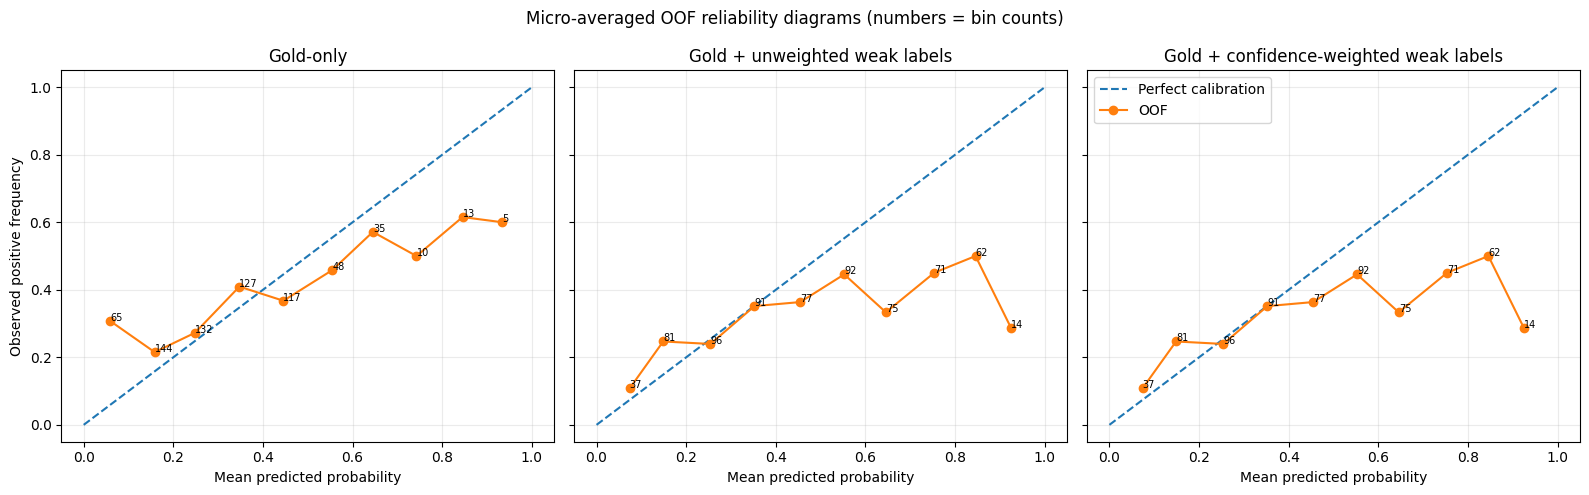

,mode,brier_score,log_loss,ece
0,gold_only,0.227244,0.665346,0.140827
1,gold_plus_confidence_weighted_weak,0.258092,0.728686,0.202638
2,gold_plus_unweighted_weak,0.258092,0.728686,0.202638


In [6]:
calibration_rows=[]
for mode in MODES:
    p=PROBS[mode]
    for j,label in enumerate(LABEL_COLS):
        y=Y[:,j]; pr=p[:,j]
        calibration_rows.append({
            "mode":mode,"finding":label,
            "brier_score":brier_score_loss(y,pr),
            "log_loss":log_loss(y,np.clip(pr,1e-7,1-1e-7),labels=[0,1]),
            "ece":ece_binary(y,pr),
            "mean_predicted_probability":float(pr.mean()),
            "observed_prevalence":float(y.mean())
        })
calibration_df=pd.DataFrame(calibration_rows)
calibration_df.to_csv(OUT_DIR/"calibration_metrics.csv",index=False)

def calibration_bins(y,p,n_bins=ECE_BINS):
    edges=np.linspace(0,1,n_bins+1)
    rows=[]
    for i in range(n_bins):
        mask=(p>=edges[i]) & ((p<edges[i+1]) if i<n_bins-1 else (p<=edges[i+1]))
        if mask.any():
            rows.append({
                "bin":i,"mean_probability":float(p[mask].mean()),
                "observed_frequency":float(y[mask].mean()),
                "count":int(mask.sum())
            })
    return pd.DataFrame(rows)

# Micro-averaged reliability diagrams pool all study-finding predictions.
fig,axes=plt.subplots(1,3,figsize=(16,5),sharex=True,sharey=True)
for ax,mode in zip(axes,MODES):
    bins=calibration_bins(Y.ravel(),PROBS[mode].ravel())
    ax.plot([0,1],[0,1],linestyle="--",label="Perfect calibration")
    if len(bins):
        ax.plot(bins["mean_probability"],bins["observed_frequency"],marker="o",label="OOF")
        for _,r in bins.iterrows():
            ax.annotate(str(int(r["count"])),(r["mean_probability"],r["observed_frequency"]),fontsize=7)
    ax.set_title(MODE_LABELS[mode])
    ax.set_xlabel("Mean predicted probability")
    ax.grid(alpha=.25)
axes[0].set_ylabel("Observed positive frequency")
axes[-1].legend()
fig.suptitle("Micro-averaged OOF reliability diagrams (numbers = bin counts)")
fig.tight_layout()
fig.savefig(OUT_DIR/"reliability_diagrams.png",dpi=160)
plt.show()
display(calibration_df.groupby("mode")[["brier_score","log_loss","ece"]].mean().reset_index())

## 7. Per-finding comparison plots

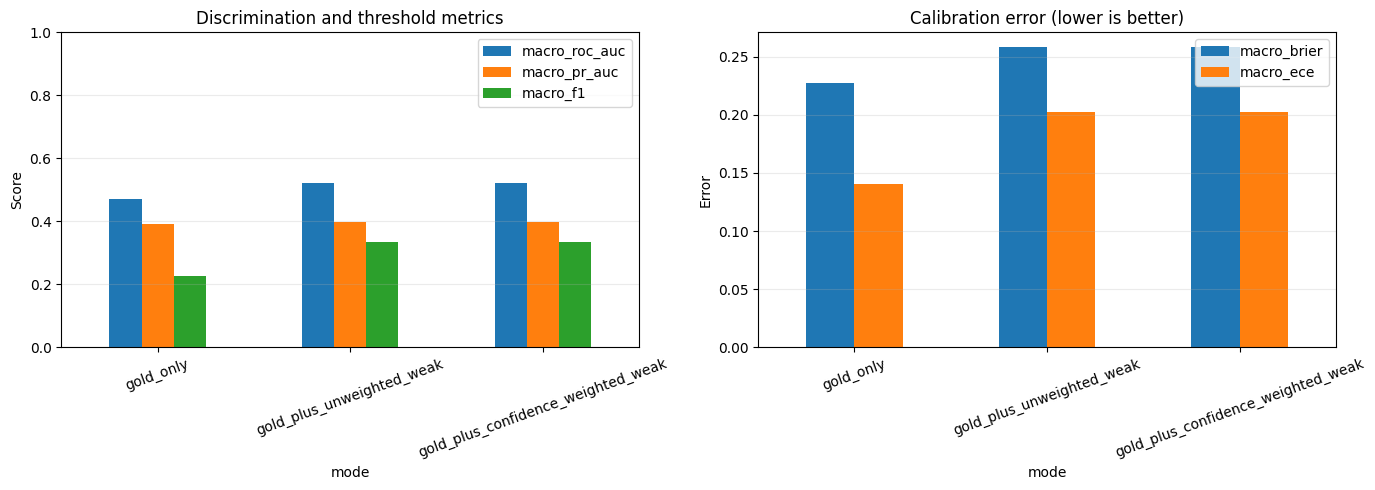

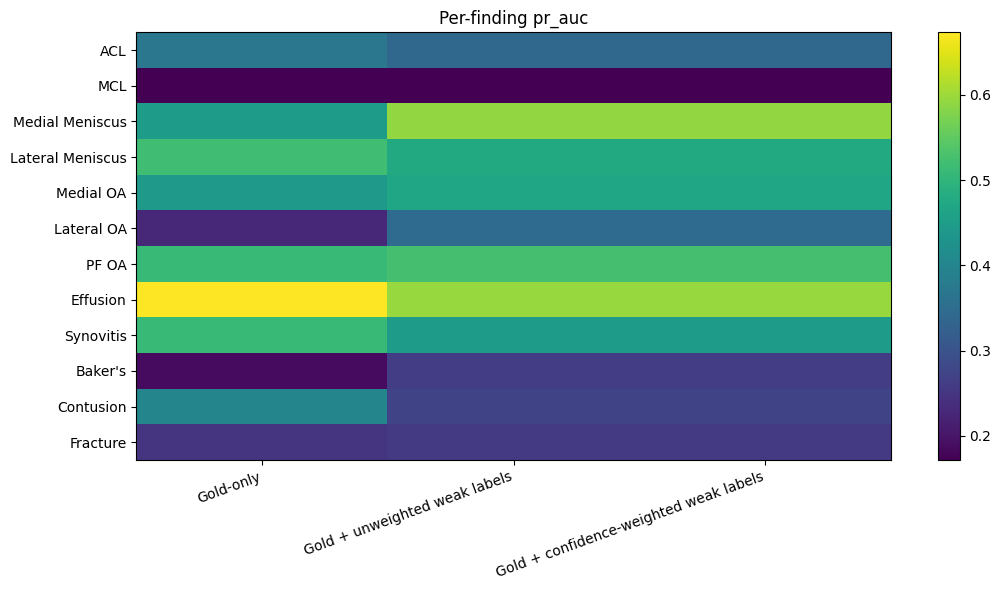

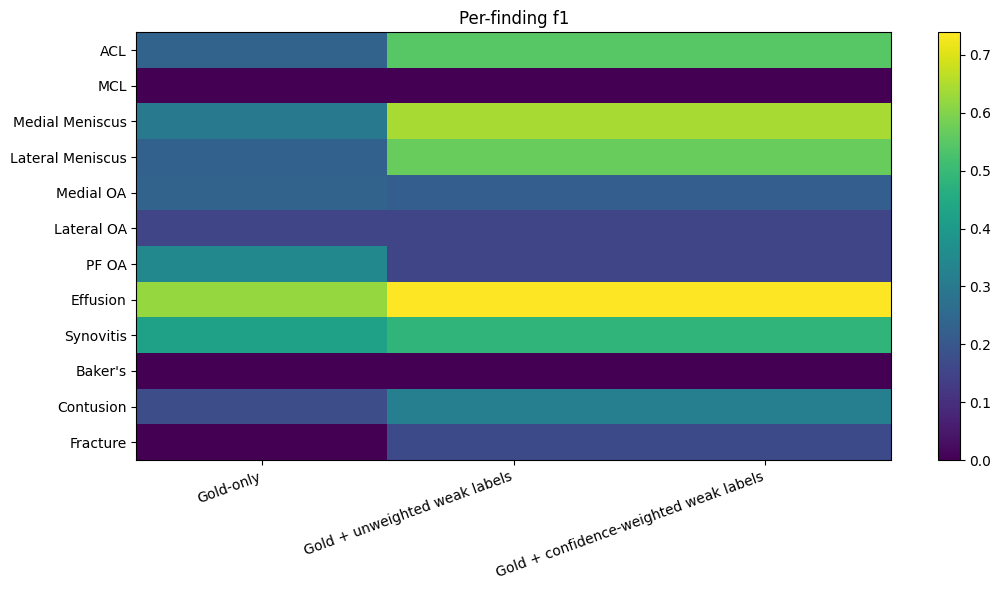

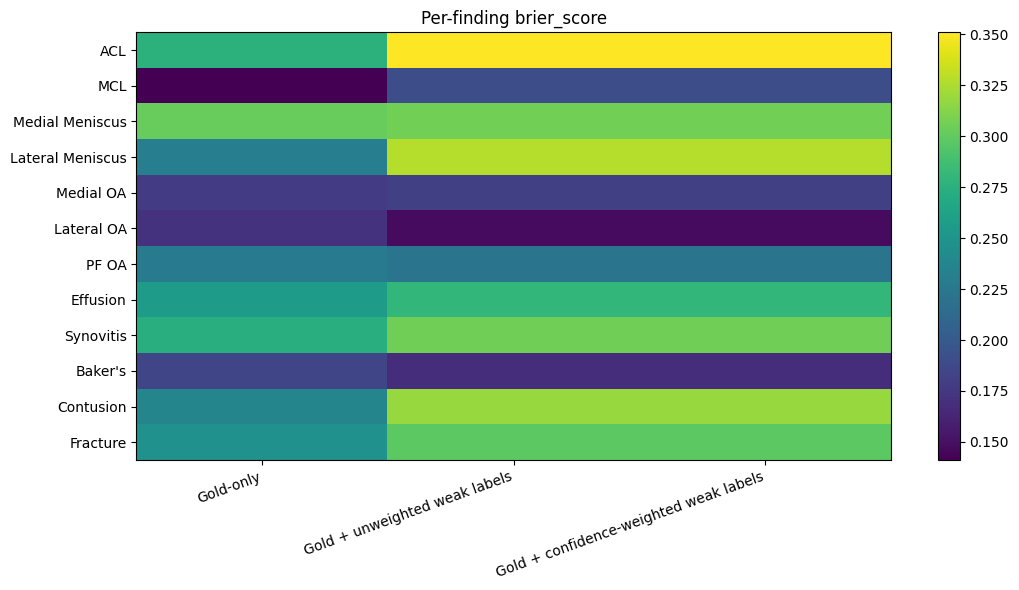

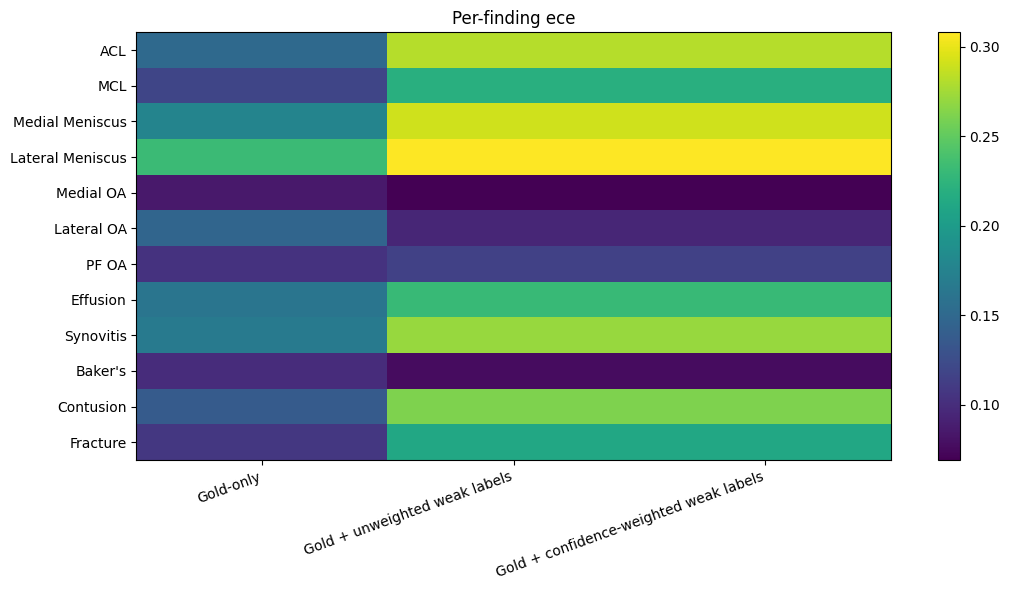

In [7]:
# Plot macro metrics across supervision modes.
plot_metrics=["macro_roc_auc","macro_pr_auc","macro_f1","macro_brier","macro_ece"]
plot_df=summary_df.set_index("mode")[plot_metrics]
fig,axes=plt.subplots(1,2,figsize=(14,5))
plot_df[["macro_roc_auc","macro_pr_auc","macro_f1"]].plot(kind="bar",ax=axes[0])
axes[0].set_title("Discrimination and threshold metrics")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0,1)
axes[0].tick_params(axis="x",rotation=20)
axes[0].grid(axis="y",alpha=.25)
plot_df[["macro_brier","macro_ece"]].plot(kind="bar",ax=axes[1])
axes[1].set_title("Calibration error (lower is better)")
axes[1].set_ylabel("Error")
axes[1].tick_params(axis="x",rotation=20)
axes[1].grid(axis="y",alpha=.25)
fig.tight_layout()
fig.savefig(OUT_DIR/"overall_metric_comparison.png",dpi=160)
plt.show()

# Heatmap-like image using matplotlib imshow defaults.
for metric in ["pr_auc","f1","brier_score","ece"]:
    pivot=per_finding_df.pivot(index="finding",columns="mode",values=metric).reindex(LABEL_COLS)
    fig,ax=plt.subplots(figsize=(11,6))
    im=ax.imshow(pivot.to_numpy(dtype=float),aspect="auto")
    ax.set_xticks(range(len(MODES)),[MODE_LABELS[m] for m in MODES],rotation=20,ha="right")
    ax.set_yticks(range(len(LABEL_COLS)),LABEL_COLS)
    ax.set_title(f"Per-finding {metric}")
    fig.colorbar(im,ax=ax)
    fig.tight_layout()
    fig.savefig(OUT_DIR/f"per_finding_{metric}_heatmap.png",dpi=160)
    plt.show()

## 8. Statistical interpretation helper

This cell creates a concise machine-readable comparison. It does not automatically declare a winner: interpret the point estimates together with paired bootstrap intervals, calibration, and the small sample size.

In [8]:
interpretation_rows=[]
for _,r in paired_differences_df.iterrows():
    lo,hi=r["ci_2_5"],r["ci_97_5"]
    metric=r["metric"]
    beneficial = (lo>0) if metric in ["macro_roc_auc","macro_pr_auc","macro_f1"] else (hi<0)
    harmful = (hi<0) if metric in ["macro_roc_auc","macro_pr_auc","macro_f1"] else (lo>0)
    if beneficial:
        conclusion="Bootstrap interval favors report-augmented method"
    elif harmful:
        conclusion="Bootstrap interval favors gold-only baseline"
    else:
        conclusion="Interval includes zero; no clear paired difference"
    interpretation_rows.append({**r.to_dict(),"interval_interpretation":conclusion})
interpretation_df=pd.DataFrame(interpretation_rows)
interpretation_df.to_csv(OUT_DIR/"statistical_interpretation.csv",index=False)
display(interpretation_df)

,comparison,metric,difference,ci_2_5,ci_97_5,bootstrap_replicates,direction_of_benefit,interval_interpretation
0,gold_plus_unweighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023399,0.123188,2000,higher,Interval includes zero; no clear paired differ...
1,gold_plus_unweighted_weak vs gold_only,macro_pr_auc,0.004546,-0.057367,0.073363,2000,higher,Interval includes zero; no clear paired differ...
2,gold_plus_unweighted_weak vs gold_only,macro_f1,0.106471,0.005461,0.214172,2000,higher,Bootstrap interval favors report-augmented method
3,gold_plus_unweighted_weak vs gold_only,macro_brier,0.030849,0.004249,0.055870,2000,lower,Bootstrap interval favors gold-only baseline
4,gold_plus_unweighted_weak vs gold_only,macro_ece,0.061812,0.013001,0.097388,2000,lower,Bootstrap interval favors gold-only baseline
5,gold_plus_confidence_weighted_weak vs gold_only,macro_roc_auc,0.049144,-0.023778,0.127170,2000,higher,Interval includes zero; no clear paired differ...
6,gold_plus_confidence_weighted_weak vs gold_only,macro_pr_auc,0.004546,-0.059725,0.071348,2000,higher,Interval includes zero; no clear paired differ...
7,gold_plus_confidence_weighted_weak vs gold_only,macro_f1,0.106471,0.003565,0.212862,2000,higher,Bootstrap interval favors report-augmented method
8,gold_plus_confidence_weighted_weak vs gold_only,macro_brier,0.030849,0.004317,0.057267,2000,lower,Bootstrap interval favors gold-only baseline
9,gold_plus_confidence_weighted_weak vs gold_only,macro_ece,0.061812,0.011374,0.098675,2000,lower,Bootstrap interval favors gold-only baseline


## 9. Save final evaluation summary and audit

Expected outputs include overall/per-finding/fold metrics, calibration results, bootstrap intervals, paired comparisons, plots and a JSON summary.

In [9]:
expected_files = [
    "overall_metrics.csv",
    "per_finding_metrics.csv",
    "fold_wise_metrics.csv",
    "bootstrap_confidence_intervals.csv",
    "paired_bootstrap_differences.csv",
    "calibration_metrics.csv",
    "reliability_diagrams.png",
    "overall_metric_comparison.png",
    "per_finding_pr_auc_heatmap.png",
    "per_finding_f1_heatmap.png",
    "per_finding_brier_score_heatmap.png",
    "per_finding_ece_heatmap.png",
    "statistical_interpretation.csv"
]
missing=[f for f in expected_files if not (OUT_DIR/f).exists()]
run_summary={
    "notebook":"14_evaluation_calibration_statistics.ipynb",
    "status":"completed" if not missing else "incomplete",
    "scope":"58 gold-labelled studies; OOF evaluation from Notebook 13",
    "n_studies":len(IDS),
    "n_findings":len(LABEL_COLS),
    "modes":MODES,
    "fold_counts":fold_counts.to_dict(),
    "threshold":THRESHOLD,
    "bootstrap_replicates":N_BOOTSTRAP,
    "bootstrap_unit":"study",
    "confidence_interval":"percentile 95%",
    "calibration":"descriptive OOF analysis; no in-sample fitted calibrator",
    "missing_artifacts":missing
}
with open(OUT_DIR/"run_summary.json","w") as f:
    json.dump(run_summary,f,indent=2)
print(json.dumps(run_summary,indent=2))
if missing:
    raise RuntimeError(f"Missing expected artifacts: {missing}")
print("\nNOTEBOOK 14 COMPLETED SUCCESSFULLY.")

{
  "notebook": "14_evaluation_calibration_statistics.ipynb",
  "status": "completed",
  "scope": "58 gold-labelled studies; OOF evaluation from Notebook 13",
  "n_studies": 58,
  "n_findings": 12,
  "modes": [
    "gold_only",
    "gold_plus_unweighted_weak",
    "gold_plus_confidence_weighted_weak"
  ],
  "fold_counts": {
    "0": 12,
    "1": 12,
    "2": 12,
    "3": 11,
    "4": 11
  },
  "threshold": 0.5,
  "bootstrap_replicates": 2000,
  "bootstrap_unit": "study",
  "confidence_interval": "percentile 95%",
  "calibration": "descriptive OOF analysis; no in-sample fitted calibrator",
  "missing_artifacts": []
}

NOTEBOOK 14 COMPLETED SUCCESSFULLY.


## 10. Reporting guidance

When writing results:
- Report macro ROC-AUC, macro PR-AUC, macro F1, macro Brier score and macro ECE.
- Include per-finding results because class prevalence differs substantially.
- Include paired bootstrap confidence intervals for differences versus gold-only.
- Describe the five folds and the 58-study sample size.
- Treat results as internal cross-validation evidence, not external clinical validation.
- Do not claim that weak supervision improves performance unless the observed metrics and paired intervals support that conclusion.
- Do not claim report-only MRI studies were used; this experiment evaluated the current 58-study embedding scope.
- Do not select a probability threshold on the same OOF predictions and then report its performance as unbiased. If threshold tuning is needed, do it within the training portion of each outer fold and regenerate OOF predictions.

In [10]:
import os

ROOT = "/kaggle/working"

print("WORKING DIRECTORY:", ROOT)
print("=" * 65)

file_count = 0

for current_dir, dirs, files in os.walk(ROOT):
    level = current_dir.replace(ROOT, "").count(os.sep)
    indent = "    " * level

    print(f"{indent}{os.path.basename(current_dir)}/")

    for filename in sorted(files):
        path = os.path.join(current_dir, filename)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{indent}    {filename} ({size_mb:.2f} MB)")
        file_count += 1

print("=" * 65)
print("TOTAL FILES:", file_count)

if file_count == 0:
    print("WARNING: No output files found.")

WORKING DIRECTORY: /kaggle/working
working/
    __notebook__.ipynb (0.51 MB)
    14_evaluation/
        bootstrap_confidence_intervals.csv (0.00 MB)
        calibration_metrics.csv (0.00 MB)
        fold_wise_metrics.csv (0.00 MB)
        overall_metric_comparison.png (0.08 MB)
        overall_metrics.csv (0.00 MB)
        paired_bootstrap_differences.csv (0.00 MB)
        per_finding_brier_score_heatmap.png (0.09 MB)
        per_finding_ece_heatmap.png (0.08 MB)
        per_finding_f1_heatmap.png (0.08 MB)
        per_finding_metrics.csv (0.01 MB)
        per_finding_pr_auc_heatmap.png (0.08 MB)
        reliability_diagrams.png (0.14 MB)
        run_summary.json (0.00 MB)
        statistical_interpretation.csv (0.00 MB)
TOTAL FILES: 15
